# Step 1: General Description of the Flying Drones Sector (Team 28)

**Course:** Innovation Management (`01TXIWS`, A.Y. 2026/27 · Politecnico di Torino)  
**Lecturer:** Prof. Grazia Sveva Ascione · **Tutor:** Dr. Giacomo Masali  
**Sector:** Flying Drones (UAVs) · **Client:** Leonardo S.p.A.

| Deck Question (PW Slide 11) | Measurement & Outputs |
|---|---|
| **Q1.** How big is the field, and is it growing, flat or declining? | Annual DOCDB families & applications (all + via PCT); 3 dating conventions; sector vs. all-patents growth (%), CAGR, and global patent share (excluding truncated years) |
| **Q2.** Which technologies make up the field? Which classes dominate, and how is the mix shifting? | Fractional counts by CPC subclass (with official CPC definitions) & WIPO 5 sectors / 35 fields; early-vs-recent period shift (pp) |
| **Q3.** Where is it happening? | IP5 filing offices (application shares + family counts); fractional applicant & inventor countries; applicant-minus-inventor ownership/R&D gap; missing-country audit |
| **Q4.** Is the field patent-heavy, or does it rely on secrecy? | Covered in companion notebook `02_step1_q4_patents_vs_secrecy_team28.ipynb` using the **exact same locked Step 0 family set** |

> **Single-source-of-truth guarantee:** Set `STEP0_CSV_PATH` to Samuele's finalized Step 0 export (`data/raw/00_family_roster.csv`) so that every Step 1, Q4, and Step 2 slide uses the exact same DOCDB family counts. If the CSV is not present yet, the notebook falls back transparently to `config/sector.yaml` (CPC ∪ IPC core + keyword-gated boundary rescue).


## 1. Setup, Configuration & Step 0 Family Universe


In [1]:
import sys
from pathlib import Path

# Ensure repository root is importable regardless of working directory on TIP
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
    TLS230_APPLN_TECHN_FIELD,
    TLS901_TECHN_FIELD_IPC,
)

from src.config_loader import (
    get_cpc_subclass_definition,
    get_last_complete_year,
    load_config,
)
from src.step0_loader import get_step0_families, iter_batches
from src.step1_metrics import (
    compute_applicant_inventor_gap,
    compute_fractional_counts,
    compute_growth_summary,
    compute_period_mix_shift,
    compute_sector_share_of_all_patents,
    compute_share_table,
    flag_truncated_years,
    pool_top_categories,
)

# ------------------------------------------------------------------ Run switches
ENV = "PROD"                      # Develop on "TEST"; switch to "PROD" for final deck numbers
STEP0_CSV_PATH = None             # Auto-detects data/raw/00_family_roster.csv if present
INCLUDE_BOUNDARY_RESCUE = True    # Used only if falling back to live YAML query (when CSV is absent)
BATCH_SIZE = 5000                 # Chunk size for SQL IN clauses on TIP

cfg = load_config(REPO_ROOT / "config" / "sector.yaml")
SECTOR_NAME = cfg["project"]["sector_name"]
YEAR_MIN = int(cfg["time_window"]["year_min"])
YEAR_MAX = int(cfg["time_window"]["year_max"])
LAST_COMPLETE_YEAR = get_last_complete_year(cfg)
IPR_TYPE = cfg["counting_rules"]["ipr_type"]
IP5_OFFICES = tuple(cfg["counting_rules"]["ip5_offices"])
TOP_N = int(cfg["counting_rules"]["top_n_categories"])

OUTPUT_DIR = REPO_ROOT / "outputs" / "step1_flying_drones"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

patstat = PatstatClient(env=ENV)
db = patstat.orm()

print(f"Environment        : {ENV}")
print(f"Sector / Client    : {SECTOR_NAME} / {cfg['project']['client_name']}")
print(f"Window (complete)  : {YEAR_MIN}–{YEAR_MAX} (complete through {LAST_COMPLETE_YEAR}; last {YEAR_MAX - LAST_COMPLETE_YEAR} yrs truncated)")
print(f"Outputs directory  : {OUTPUT_DIR}")


Environment        : PROD
Sector / Client    : Flying drones / Leonardo S.p.A.
Window (complete)  : 2004–2025 (complete through 2022; last 3 yrs truncated)
Outputs directory  : /home/jovyan/Patent-study/outputs/step1_flying_drones


In [2]:
# Load locked Step 0 DOCDB families (or live fallback from config/sector.yaml)
step0_df, step0_source = get_step0_families(
    patstat=patstat,
    db=db,
    cfg=cfg,
    override_csv_path=STEP0_CSV_PATH,
    include_boundary_rescue=INCLUDE_BOUNDARY_RESCUE,
)
sector_family_ids = step0_df["docdb_family_id"].astype(int).tolist()

print(f"Step 0 source           : {step0_source}")
print(f"Distinct DOCDB families : {len(sector_family_ids):,}")
display(step0_df["query_source"].value_counts().rename("families").to_frame())


Step 0 source           : locked_csv:../data/raw/00_family_roster.csv
Distinct DOCDB families : 71,197


,families
query_source,
core,61967
boundary_rescue,9230


## 2. Batched PATSTAT Extraction (Applications, CPC, WIPO Fields, Persons)

All tables for the locked UAV families are fetched in safe 5,000-family chunks so `PROD` runs reliably without hitting SQL `IN`-clause size limits. Only small summary tables and plots are written to `outputs/step1_flying_drones/` (no bulk PATSTAT extracts committed to Git).


In [3]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))


def fetch_batched(query_builder, family_ids, batch_size=BATCH_SIZE):
    frames = []
    for batch in iter_batches(family_ids, batch_size=batch_size):
        df_chunk = patstat.df(query_builder(batch))
        if df_chunk is not None and not df_chunk.empty:
            frames.append(df_chunk)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


# 2.1 Sector applications (TLS201_APPLN)
applns_raw = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_kind,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
        case((IS_PCT_APPLN, 1), else_=0).label("is_pct"),
    ).filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    ),
    sector_family_ids,
)

# Restrict to valid window on family earliest priority year (consistent with Step 0)
fam_years = (
    applns_raw.groupby("docdb_family_id", as_index=False)
    .agg(
        family_year=("earliest_filing_year", "min"),
        is_pct=("is_pct", "max"),
        is_granted=("granted", lambda s: int((s == "Y").any())),
        family_size=("docdb_family_size", "max"),
    )
)
fam_years = fam_years[fam_years["family_year"].between(YEAR_MIN, YEAR_MAX)].copy()
valid_fids = set(fam_years["docdb_family_id"].astype(int).tolist())

applns = applns_raw[
    applns_raw["docdb_family_id"].isin(valid_fids)
    & applns_raw["appln_filing_year"].between(YEAR_MIN, YEAR_MAX)
].copy()

print(f"Valid UAV families ({YEAR_MIN}–{YEAR_MAX})    : {len(fam_years):,}")
print(f"Valid UAV applications ({YEAR_MIN}–{YEAR_MAX}): {len(applns):,}")
print(f"Avg applications per family        : {len(applns) / max(len(fam_years), 1):.2f}")


Valid UAV families (2004–2025)    : 71,190
Valid UAV applications (2004–2025): 116,317
Avg applications per family        : 1.63


In [4]:
# 2.2 Global 'All Patents' benchmark counts (computed directly inside PATSTAT)
all_fam_year = func.min(TLS201_APPLN.earliest_filing_year)
q_all_fam = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        all_fam_year.label("year"),
        func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
    )
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE)
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(all_fam_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)
all_patents_fam = patstat.df(
    db.query(
        q_all_fam.c.year,
        func.count().label("n_all"),
        func.sum(q_all_fam.c.is_pct).label("n_pct"),
    ).group_by(q_all_fam.c.year).order_by(q_all_fam.c.year)
)

all_patents_appln = patstat.df(
    db.query(
        TLS201_APPLN.appln_filing_year.label("year"),
        func.count(distinct(TLS201_APPLN.appln_id)).label("n_all"),
        func.sum(case((IS_PCT_APPLN, 1), else_=0)).label("n_pct"),
    )
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.appln_filing_year.between(YEAR_MIN, YEAR_MAX),
    )
    .group_by(TLS201_APPLN.appln_filing_year)
    .order_by(TLS201_APPLN.appln_filing_year)
)
print("Global benchmark extracted successfully.")


Global benchmark extracted successfully.


## 3. Q1 — How Big Is the Field, and Is It Growing, Flat, or Declining?


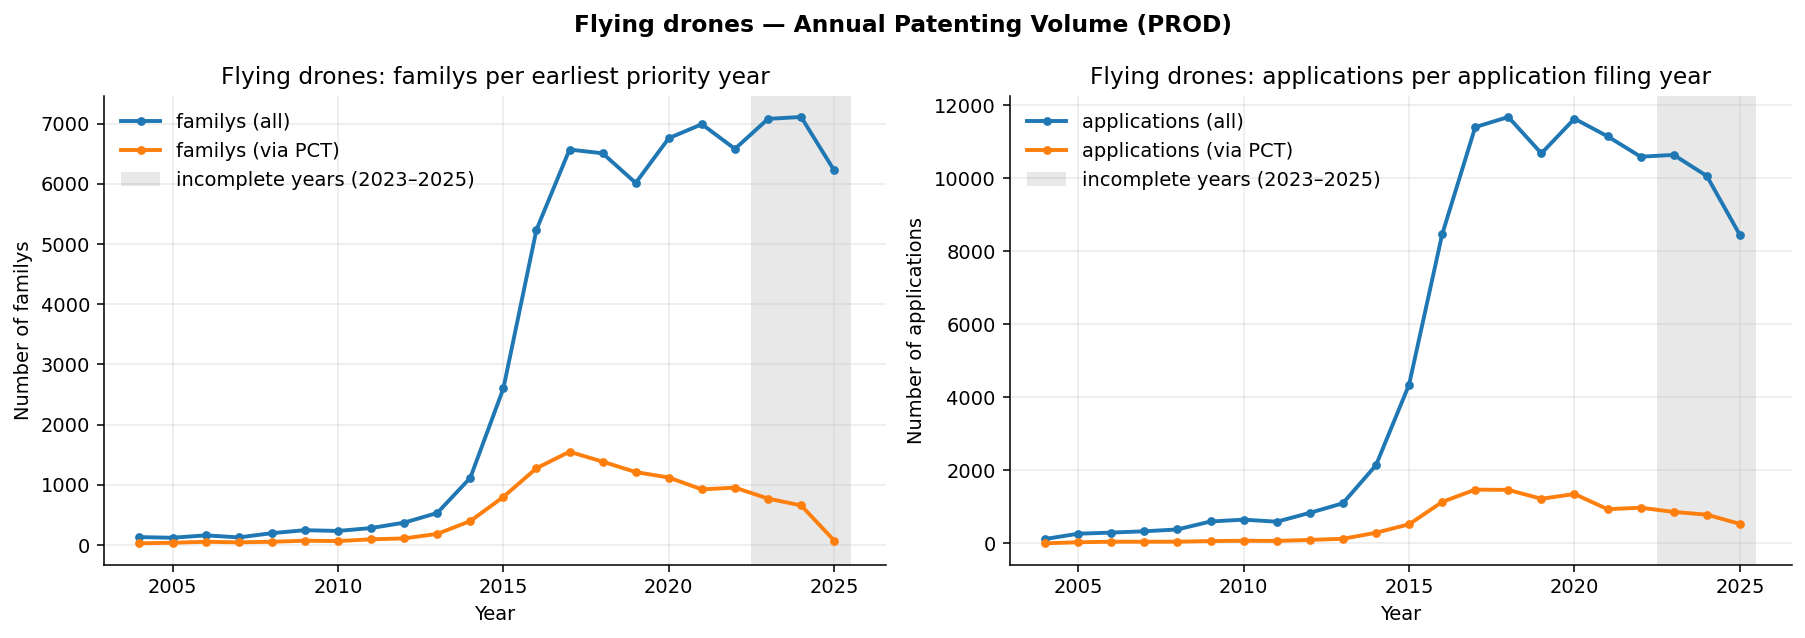

In [5]:
def shade_truncated(ax):
    ax.axvspan(
        LAST_COMPLETE_YEAR + 0.5,
        YEAR_MAX + 0.5,
        color="grey",
        alpha=0.18,
        lw=0,
        label=f"incomplete years ({LAST_COMPLETE_YEAR + 1}–{YEAR_MAX})",
    )


# Assemble unified volume table (sector + all patents, family + application, all + via PCT)
vol_parts = [
    fam_years.groupby("family_year").size().reset_index(name="n").rename(columns={"family_year": "year"}).assign(scope=SECTOR_NAME, level="family", series="all"),
    fam_years[fam_years["is_pct"] == 1].groupby("family_year").size().reset_index(name="n").rename(columns={"family_year": "year"}).assign(scope=SECTOR_NAME, level="family", series="via PCT"),
    applns.groupby("appln_filing_year")["appln_id"].nunique().reset_index(name="n").rename(columns={"appln_filing_year": "year"}).assign(scope=SECTOR_NAME, level="application", series="all"),
    applns[applns["is_pct"] == 1].groupby("appln_filing_year")["appln_id"].nunique().reset_index(name="n").rename(columns={"appln_filing_year": "year"}).assign(scope=SECTOR_NAME, level="application", series="via PCT"),
    all_patents_fam[["year", "n_all"]].rename(columns={"n_all": "n"}).assign(scope="all patents", level="family", series="all"),
    all_patents_fam[["year", "n_pct"]].rename(columns={"n_pct": "n"}).assign(scope="all patents", level="family", series="via PCT"),
    all_patents_appln[["year", "n_all"]].rename(columns={"n_all": "n"}).assign(scope="all patents", level="application", series="all"),
    all_patents_appln[["year", "n_pct"]].rename(columns={"n_pct": "n"}).assign(scope="all patents", level="application", series="via PCT"),
]
volume_df = flag_truncated_years(pd.concat(vol_parts, ignore_index=True), LAST_COMPLETE_YEAR)
volume_df.to_csv(OUTPUT_DIR / "volume_per_year.csv", index=False)

# Figure 1: Annual volume (families & applications, all + via PCT)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True)
for ax, lvl, xlabel_col in zip(axes, ("family", "application"), ("earliest priority year", "application filing year")):
    sub = volume_df[(volume_df["scope"] == SECTOR_NAME) & (volume_df["level"] == lvl)]
    for ser, grp in sub.groupby("series"):
        grp = grp.sort_values("year")
        ax.plot(grp["year"], grp["n"], marker="o", ms=3.5, lw=2, label=f"{lvl}s ({ser})")
    shade_truncated(ax)
    ax.set(title=f"{SECTOR_NAME}: {lvl}s per {xlabel_col}", xlabel="Year", ylabel=f"Number of {lvl}s")
    ax.legend(frameon=False)
fig.suptitle(f"{SECTOR_NAME} — Annual Patenting Volume ({ENV})", fontweight="bold")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig01_volume_per_year.png", bbox_inches="tight")
plt.show()


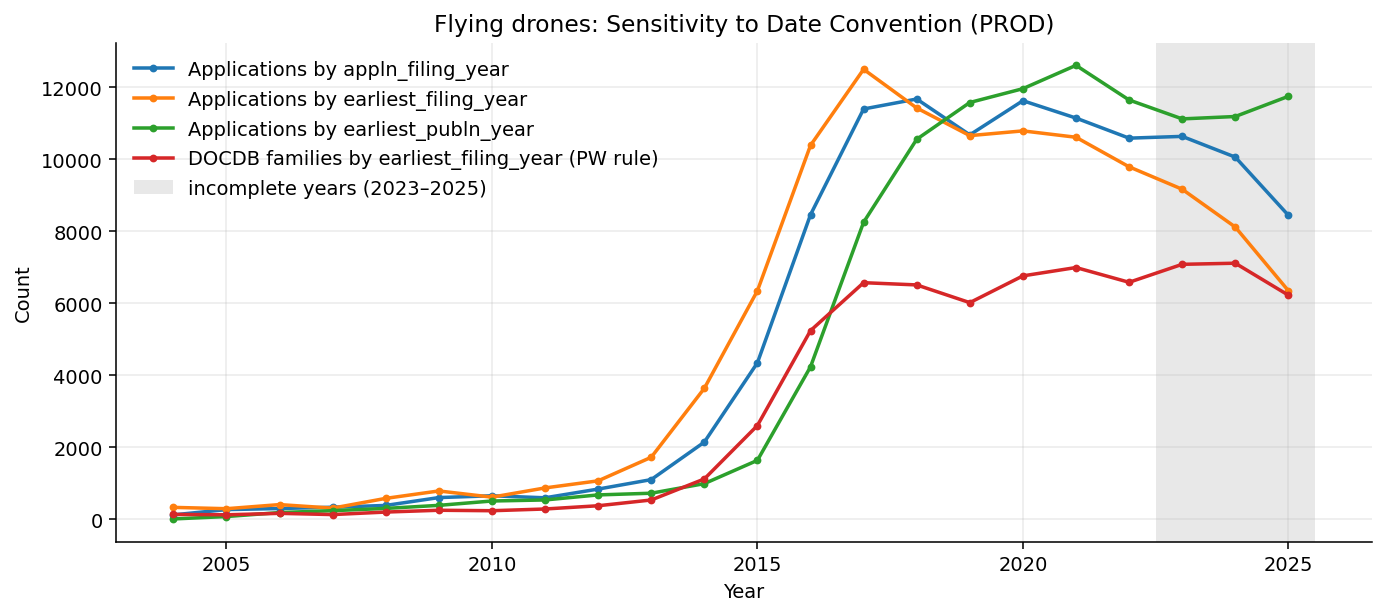

In [6]:
# Figure 2: Three dating conventions (Appendix check)
dating_parts = [
    applns_raw[applns_raw["docdb_family_id"].isin(valid_fids) & applns_raw[col].between(YEAR_MIN, YEAR_MAX)]
    .groupby(col)["appln_id"].nunique().reset_index(name="n").rename(columns={col: "year"})
    .assign(series=f"Applications by {col}")
    for col in ("appln_filing_year", "earliest_publn_year", "earliest_filing_year")
]
dating_parts.append(
    fam_years.groupby("family_year").size().reset_index(name="n").rename(columns={"family_year": "year"})
    .assign(series="DOCDB families by earliest_filing_year (PW rule)")
)
dating_df = pd.concat(dating_parts, ignore_index=True)
dating_df.to_csv(OUTPUT_DIR / "dating_conventions.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
for ser, grp in dating_df.groupby("series"):
    grp = grp.sort_values("year")
    ax.plot(grp["year"], grp["n"], marker="o", ms=3, lw=1.8, label=ser)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: Sensitivity to Date Convention ({ENV})", xlabel="Year", ylabel="Count")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig02_dating_conventions.png", bbox_inches="tight")
plt.show()


count_2004  count_2022  total_complete_window  \
level       scope                                                          
family      all patents     1000554.0   2389326.0             30933245.0   
            Flying drones       133.0      6579.0                50782.0   
application all patents     1818031.0   3526192.0             50241446.0   
            Flying drones       120.0     10582.0                87191.0   

                           peak_complete_year  peak_complete_count  \
level       scope                                                    
family      all patents                  2022            2389326.0   
            Flying drones                2021               6989.0   
application all patents                  2020            3539769.0   
            Flying drones                2018              11669.0   

                           growth_2004_2022_pct  cagr_2004_2022_pct  
level       scope                                                    
family      all patents                  138.80                4.95  
            Flying drones               4846.62               24.20  
application all patents                   93.96                3.75  
            Flying drones               8718.33               28.26

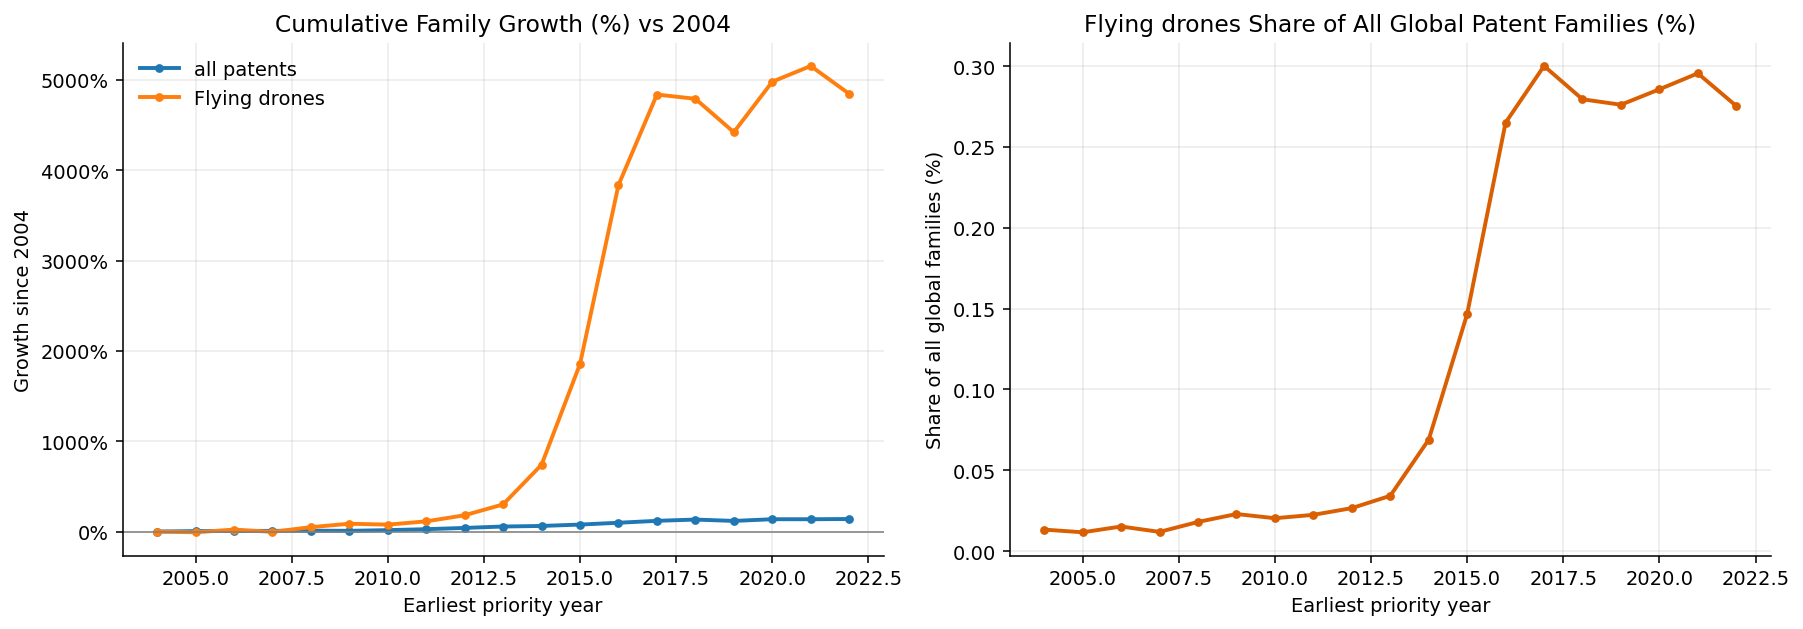

In [7]:
# Growth comparison (Sector vs All Patents, complete years only) + global share
growth_summary = compute_growth_summary(
    volume_df,
    sector_name=SECTOR_NAME,
    year_min=YEAR_MIN,
    last_complete_year=LAST_COMPLETE_YEAR,
)
growth_summary.to_csv(OUTPUT_DIR / "growth_summary.csv")
display(growth_summary.round(2))

share_of_all = compute_sector_share_of_all_patents(
    volume_df,
    sector_name=SECTOR_NAME,
    last_complete_year=LAST_COMPLETE_YEAR,
)
share_of_all.to_csv(OUTPUT_DIR / "sector_share_of_all_patents.csv", index=False)

# Figure 3: Cumulative growth (%) since first nonzero year in window + sector share of all patents
totals = volume_df[(volume_df["series"] == "all") & (volume_df["year"].between(YEAR_MIN, LAST_COMPLETE_YEAR))].pivot_table(
    index="year", columns=["level", "scope"], values="n"
).sort_index()
base_year = int(totals[("family", SECTOR_NAME)].dropna().loc[lambda s: s > 0].index.min())
growth_path = (totals.loc[base_year:] / totals.loc[base_year] - 1.0) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for scope_name in ("all patents", SECTOR_NAME):
    axes[0].plot(growth_path.index, growth_path[("family", scope_name)], marker="o", ms=3.5, lw=2, label=scope_name)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set(title=f"Cumulative Family Growth (%) vs {base_year}", xlabel="Earliest priority year", ylabel=f"Growth since {base_year}")
axes[0].yaxis.set_major_formatter(PercentFormatter(100))
axes[0].legend(frameon=False)

fam_share = share_of_all[share_of_all["level"] == "family"].sort_values("year")
axes[1].plot(fam_share["year"], fam_share["sector_share_pct"], marker="o", ms=3.5, lw=2, color="#d95f02")
axes[1].set(title=f"{SECTOR_NAME} Share of All Global Patent Families (%)", xlabel="Earliest priority year", ylabel="Share of all global families (%)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig03_growth_vs_all_patents.png", bbox_inches="tight")
plt.show()


## 4. Q2 — Which Technologies Make Up the Field, and How Is the Mix Shifting?


,family,application,official_definition
subclass,,,
B64U,20.89,21.37,Unmanned aerial vehicles [UAVs]; equipment the...
G05D,16.94,14.08,Systems for controlling or regulating non-elec...
B64C,14.58,12.74,Aeroplanes; helicopters (incl. legacy RPV code...
B64D,9.43,8.52,Equipment for fitting in or to aircraft; flyin...
Y02T,3.82,3.45,Check official CPC scheme (cooperativepatentcl...
G08G,3.29,4.00,"Traffic control systems (UTM, air traffic mana..."
B64F,2.03,2.05,Ground or aircraft-carrier-deck installations ...
G01S,1.45,0.00,Radio direction-finding; radar; lidar; sonar; ...
H04N,0.00,1.75,"Pictorial communication (aerial cameras, gimba..."


CPC Subclass Shift (2004–2012 -> 2018–2022):


,count_2004_2012,count_2018_2022,share_2004_2012_pct,share_2018_2022_pct,shift_pp,official_cpc_definition
subclass,,,,,,
Other,452.57,8260.12,26.75,27.25,0.50,All remaining co-classified CPC subclasses pooled
G05D,187.82,5634.05,11.10,18.59,7.49,Systems for controlling or regulating non-elec...
B64U,486.32,5599.01,28.74,18.47,-10.27,Unmanned aerial vehicles [UAVs]; equipment the...
B64C,255.16,4473.95,15.08,14.76,-0.32,Aeroplanes; helicopters (incl. legacy RPV code...
B64D,112.30,3037.15,6.64,10.02,3.38,Equipment for fitting in or to aircraft; flyin...
Y02T,51.06,1348.81,3.02,4.45,1.43,Check official CPC scheme (cooperativepatentcl...
G08G,68.47,902.84,4.05,2.98,-1.07,"Traffic control systems (UTM, air traffic mana..."
B64F,44.60,647.44,2.64,2.14,-0.50,Ground or aircraft-carrier-deck installations ...
G01S,33.70,408.65,1.99,1.35,-0.64,Radio direction-finding; radar; lidar; sonar; ...


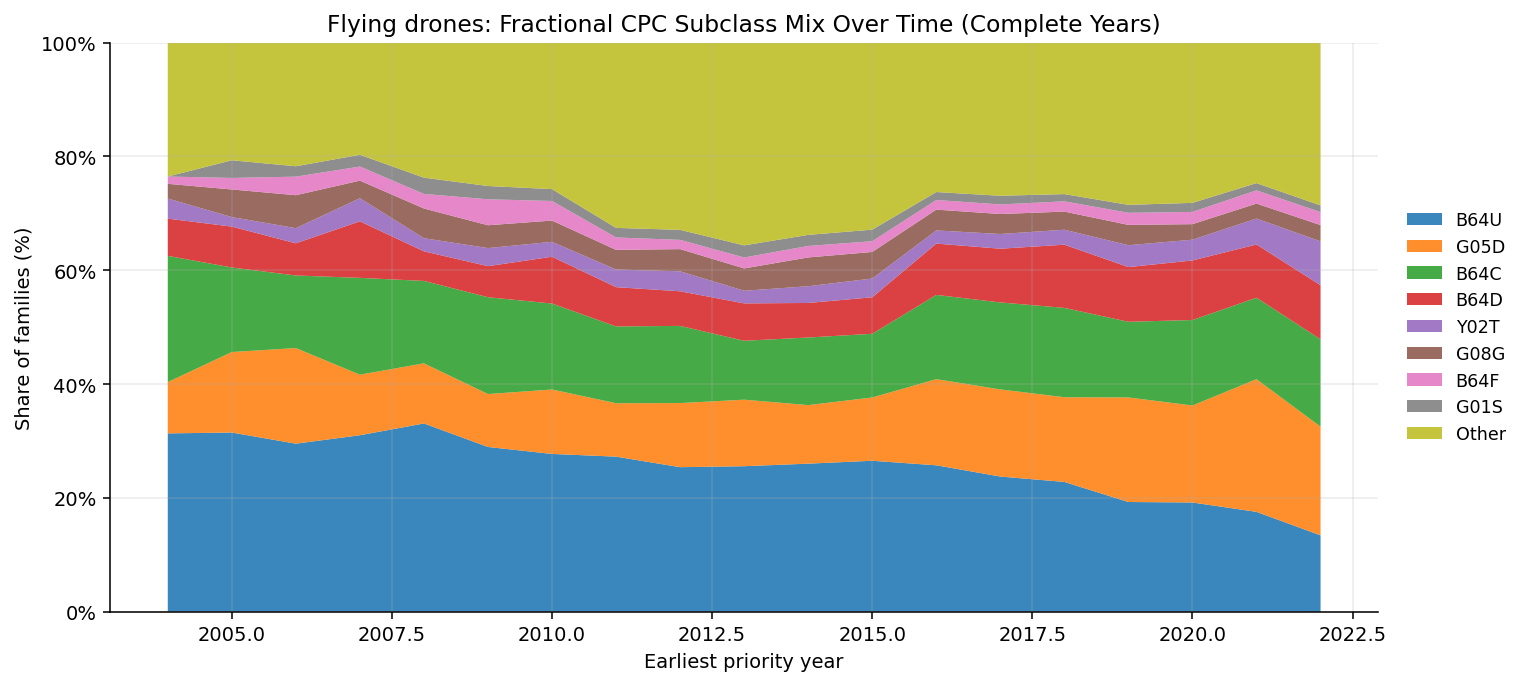

In [8]:
# 4.1 Fetch CPC symbols & WIPO technology fields for sector applications
cpc_raw = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    )
    .distinct(),
    list(valid_fids),
)
cpc_raw["subclass"] = cpc_raw["cpc_class_symbol"].astype(str).str.replace(" ", "", regex=False).str[:4]
cpc_fam = cpc_raw.merge(fam_years[["docdb_family_id", "family_year"]], on="docdb_family_id", how="inner")
cpc_appln = cpc_raw.merge(applns[["appln_id", "appln_filing_year"]], on="appln_id", how="inner")

frac_cpc_fam = compute_fractional_counts(cpc_fam, unit_col="docdb_family_id", category_col="subclass", year_col="family_year").rename(columns={"family_year": "year"})
frac_cpc_appln = compute_fractional_counts(cpc_appln, unit_col="appln_id", category_col="subclass", year_col="appln_filing_year").rename(columns={"appln_filing_year": "year"})

pooled_cpc_fam = pool_top_categories(frac_cpc_fam, "subclass", LAST_COMPLETE_YEAR, top_n=TOP_N)
pooled_cpc_appln = pool_top_categories(frac_cpc_appln, "subclass", LAST_COMPLETE_YEAR, top_n=TOP_N)

cpc_counts = pd.DataFrame({
    "family": pooled_cpc_fam[pooled_cpc_fam["year"] <= LAST_COMPLETE_YEAR].groupby("subclass")["n_frac"].sum(),
    "application": pooled_cpc_appln[pooled_cpc_appln["year"] <= LAST_COMPLETE_YEAR].groupby("subclass")["n_frac"].sum(),
}).fillna(0.0)
cpc_shares = compute_share_table(cpc_counts)
cpc_shares["official_definition"] = [
    "" if idx == "Total" else get_cpc_subclass_definition(idx, cfg) for idx in cpc_shares.index
]
cpc_shares.to_csv(OUTPUT_DIR / "cpc_subclass_shares.csv")
display(cpc_shares.round(2))

# Period shift: Early (2004–2012) vs Recent (2018–2022)
EARLY_WIN = (YEAR_MIN, min(YEAR_MIN + 8, LAST_COMPLETE_YEAR - 5))
RECENT_WIN = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)
cpc_shift = compute_period_mix_shift(
    pooled_cpc_fam, "subclass", EARLY_WIN, RECENT_WIN, cfg=cfg, attach_cpc_definitions=True
)
cpc_shift.to_csv(OUTPUT_DIR / "cpc_subclass_shift.csv")
print(f"CPC Subclass Shift ({EARLY_WIN[0]}–{EARLY_WIN[1]} -> {RECENT_WIN[0]}–{RECENT_WIN[1]}):")
display(cpc_shift.round(2))

# Figure 4: 100% stacked CPC subclass mix over time (complete years)
piv_cpc = (
    pooled_cpc_fam[pooled_cpc_fam["year"] <= LAST_COMPLETE_YEAR]
    .pivot_table(index="year", columns="subclass", values="n_frac", aggfunc="sum", fill_value=0.0)
)
piv_cpc_pct = piv_cpc.div(piv_cpc.sum(axis=1), axis=0) * 100.0
col_order = [c for c in cpc_shares.index if c not in ("Total", "Other") and c in piv_cpc_pct.columns]
if "Other" in piv_cpc_pct.columns:
    col_order.append("Other")
piv_cpc_pct = piv_cpc_pct[col_order]

fig, ax = plt.subplots(figsize=(11, 5))
ax.stackplot(piv_cpc_pct.index, piv_cpc_pct.T.values, labels=piv_cpc_pct.columns, alpha=0.88)
ax.set(title=f"{SECTOR_NAME}: Fractional CPC Subclass Mix Over Time (Complete Years)", xlabel="Earliest priority year", ylabel="Share of families (%)", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig04_cpc_subclass_mix.png", bbox_inches="tight")
plt.show()


In [9]:
# 4.2 WIPO 5 Technology Sectors & 35 Technology Fields (TLS230 + TLS901)
wipo_lookup = patstat.df(
    db.query(
        TLS901_TECHN_FIELD_IPC.techn_field_nr,
        TLS901_TECHN_FIELD_IPC.techn_field,
        TLS901_TECHN_FIELD_IPC.techn_sector,
    ).distinct()
).drop_duplicates("techn_field_nr")

wipo_raw = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS230_APPLN_TECHN_FIELD.techn_field_nr,
        TLS230_APPLN_TECHN_FIELD.weight,
    )
    .join(TLS230_APPLN_TECHN_FIELD, TLS201_APPLN.appln_id == TLS230_APPLN_TECHN_FIELD.appln_id)
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    ),
    list(valid_fids),
).merge(wipo_lookup, on="techn_field_nr", how="left")

wipo_fam = wipo_raw.merge(fam_years[["docdb_family_id", "family_year"]], on="docdb_family_id", how="inner")
wipo_fam_comp = wipo_fam[wipo_fam["family_year"] <= LAST_COMPLETE_YEAR]
# Normalize WIPO weights within each family so every family sums to 1.0
fam_w = wipo_fam_comp.groupby(["docdb_family_id", "techn_sector"], as_index=False)["weight"].sum()
fam_w["norm_w"] = fam_w["weight"] / fam_w.groupby("docdb_family_id")["weight"].transform("sum")
wipo_sector_shares = compute_share_table(fam_w.groupby("techn_sector")["norm_w"].sum().to_frame("family"))
wipo_sector_shares.to_csv(OUTPUT_DIR / "wipo_techn_sector_shares.csv")
display(wipo_sector_shares.round(2))

fam_f = wipo_fam_comp.groupby(["docdb_family_id", "techn_field"], as_index=False)["weight"].sum()
fam_f["norm_w"] = fam_f["weight"] / fam_f.groupby("docdb_family_id")["weight"].transform("sum")
top_wipo = fam_f.groupby("techn_field")["norm_w"].sum().nlargest(TOP_N).index
fam_f["field_pooled"] = fam_f["techn_field"].where(fam_f["techn_field"].isin(top_wipo), "Other")
wipo_field_shares = compute_share_table(fam_f.groupby("field_pooled")["norm_w"].sum().to_frame("family"))
wipo_field_shares.to_csv(OUTPUT_DIR / "wipo_techn_field_shares.csv")
display(wipo_field_shares.round(2))


,family
techn_sector,
Mechanical engineering,57.49
Instruments,27.19
Electrical engineering,12.69
Other fields,1.37
Chemistry,1.26
Total,100.00


,family
field_pooled,
Transport,53.17
Control,20.98
Measurement,5.28
Computer technology,3.70
"Electrical machinery, apparatus, energy",2.33
Other special machines,2.09
Digital communication,1.92
Audio-visual technology,1.84
Other,8.69


## 5. Q3 — Where Is It Happening? (IP5 Offices & Applicant vs. Inventor Countries)


IP5 share of all sector applications (complete years): 76.5%


,applications
office_grp,
CN,32.56
US,20.46
WO,11.43
KR,9.43
JP,7.43
EP,6.64
Other,12.05
Total,100.00


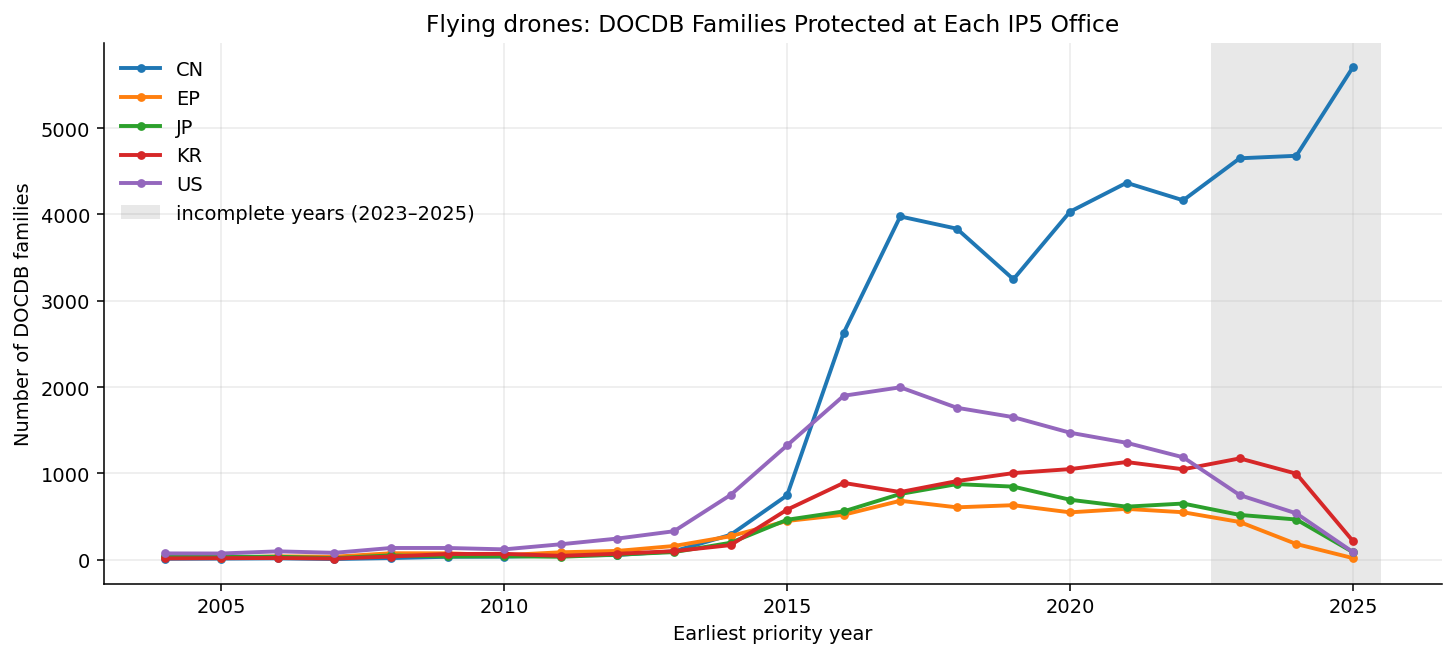

In [10]:
# 5.1 IP5 Filing Offices (Application shares & Family coverage)
applns_comp = applns[applns["appln_filing_year"] <= LAST_COMPLETE_YEAR].copy()
applns_comp["office_grp"] = applns_comp["appln_auth"].where(applns_comp["appln_auth"].isin(IP5_OFFICES + ("WO",)), "Other")
office_appln_shares = compute_share_table(
    applns_comp.groupby("office_grp")["appln_id"].nunique().to_frame("applications")
)
office_appln_shares.to_csv(OUTPUT_DIR / "office_application_shares.csv")
ip5_share_total = office_appln_shares.loc[[o for o in IP5_OFFICES if o in office_appln_shares.index], "applications"].sum()
print(f"IP5 share of all sector applications (complete years): {ip5_share_total:.1f}%")
display(office_appln_shares.round(2))

# Family counts by IP5 office over time (note: families can be filed in multiple offices)
fam_office = (
    applns_raw[applns_raw["docdb_family_id"].isin(valid_fids) & applns_raw["appln_auth"].isin(IP5_OFFICES)]
    .merge(fam_years[["docdb_family_id", "family_year"]], on="docdb_family_id", how="inner")
    .groupby(["appln_auth", "family_year"])["docdb_family_id"].nunique()
    .reset_index(name="n_families")
)
fam_office.to_csv(OUTPUT_DIR / "ip5_families_over_time.csv", index=False)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
for office, grp in fam_office.groupby("appln_auth"):
    grp = grp.sort_values("family_year")
    ax.plot(grp["family_year"], grp["n_families"], marker="o", ms=3.5, lw=2, label=office)
shade_truncated(ax)
ax.set(title=f"{SECTOR_NAME}: DOCDB Families Protected at Each IP5 Office", xlabel="Earliest priority year", ylabel="Number of DOCDB families")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig05_ip5_offices.png", bbox_inches="tight")
plt.show()


Applicant country coverage: 32,044/70,845 families (45.2%)
Inventor  country coverage: 27,966/70,785 families (39.5%)


family          application         
      applicant inventor   applicant inventor
ctry                                         
US        30.63    32.87       36.43    36.87
KR        27.15    18.88       16.99    12.04
CN        12.45    13.87       11.62    12.75
JP         8.42     9.26        7.94     8.33
DE         4.03     4.90        4.89     5.69
FR         2.73     3.03        4.14     4.33
GB         1.97     2.25        2.84     3.19
IL         1.31     1.55        2.28     2.34
Other     11.32    13.38       12.88    14.47
Total    100.00   100.00      100.00   100.00

Ownership vs R&D Geography Gap (Applicant Share minus Inventor Share, pp):


,applicant_share_pct,inventor_share_pct,ownership_minus_rd_pp
ctry,,,
US,30.63,32.87,-2.24
KR,27.15,18.88,8.27
CN,12.45,13.87,-1.42
Other,11.32,13.38,-2.07
JP,8.42,9.26,-0.84
DE,4.03,4.90,-0.87
FR,2.73,3.03,-0.30
GB,1.97,2.25,-0.29
IL,1.31,1.55,-0.24


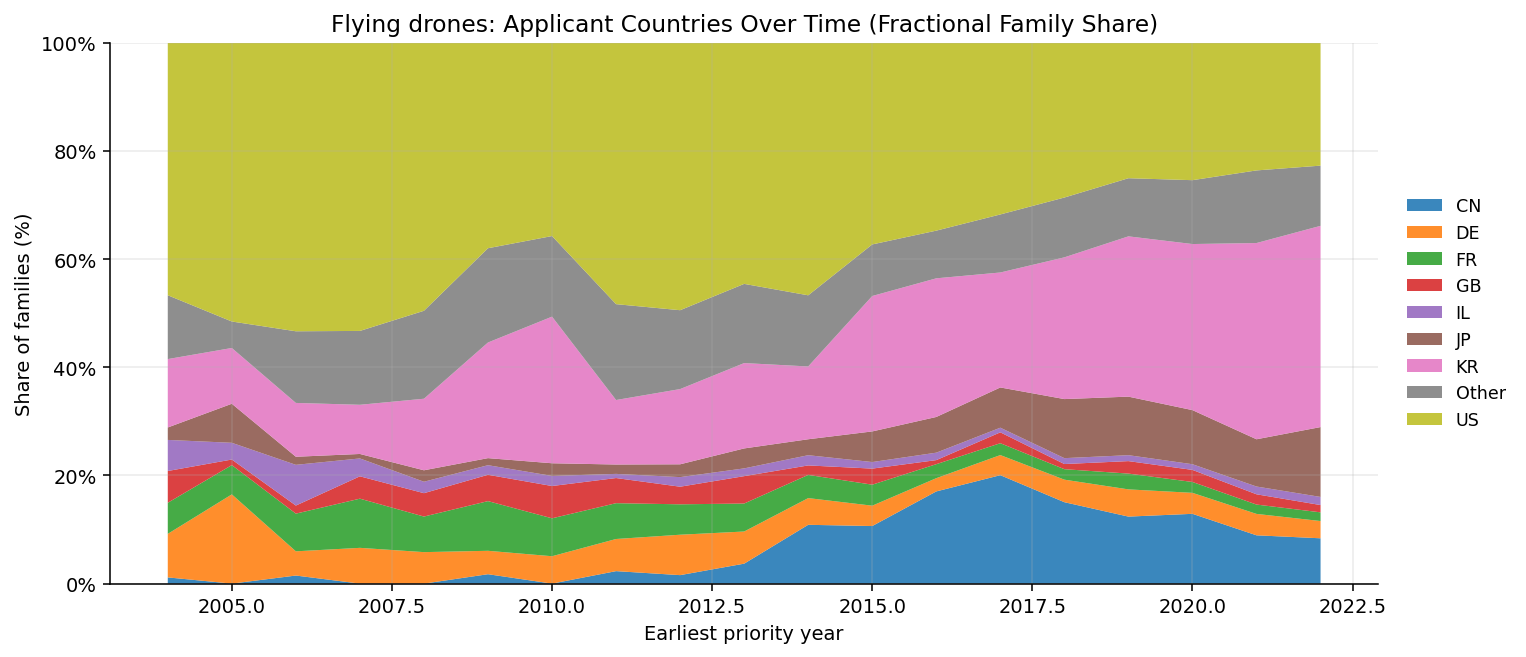

In [11]:
# 5.2 Applicant vs. Inventor Countries (Fractional Counts + Missing-Country Transparency Audit)
pers_raw = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS207_PERS_APPLN.person_id,
        TLS207_PERS_APPLN.applt_seq_nr,
        TLS207_PERS_APPLN.invt_seq_nr,
        func.trim(TLS206_PERSON.person_ctry_code).label("ctry"),
    )
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    ),
    list(valid_fids),
)
pers_raw["ctry"] = pers_raw["ctry"].fillna("").astype(str).str.strip().replace("", np.nan)
pers_fam = pers_raw.merge(fam_years[["docdb_family_id", "family_year"]], on="docdb_family_id", how="inner")

# Missing-country audit (required by Tutorial 02 §5 & §9.2)
applt_fams_total = pers_fam.loc[pers_fam["applt_seq_nr"] > 0, "docdb_family_id"].nunique()
applt_fams_known = pers_fam.loc[(pers_fam["applt_seq_nr"] > 0) & pers_fam["ctry"].notna(), "docdb_family_id"].nunique()
invt_fams_total = pers_fam.loc[pers_fam["invt_seq_nr"] > 0, "docdb_family_id"].nunique()
invt_fams_known = pers_fam.loc[(pers_fam["invt_seq_nr"] > 0) & pers_fam["ctry"].notna(), "docdb_family_id"].nunique()
print(f"Applicant country coverage: {applt_fams_known:,}/{applt_fams_total:,} families ({applt_fams_known / max(applt_fams_total, 1) * 100:.1f}%)")
print(f"Inventor  country coverage: {invt_fams_known:,}/{invt_fams_total:,} families ({invt_fams_known / max(invt_fams_total, 1) * 100:.1f}%)")

# Fractional counts proportional to distinct person_ids per family (exact Tutorial 02 rule)
def _fractional_country(df_role, unit_col, year_col):
    valid = df_role.dropna(subset=["ctry"])[[unit_col, "person_id", "ctry", year_col]].drop_duplicates()
    k = valid.groupby(unit_col)["person_id"].transform("nunique")
    valid = valid.assign(w=1.0 / k)
    return valid.groupby(["ctry", year_col], as_index=False)["w"].sum().rename(columns={year_col: "year", "w": "n_frac"})

applt_fam_ctry = _fractional_country(pers_fam[pers_fam["applt_seq_nr"] > 0], "docdb_family_id", "family_year")
invt_fam_ctry = _fractional_country(pers_fam[pers_fam["invt_seq_nr"] > 0], "docdb_family_id", "family_year")

pers_appln = pers_raw.merge(applns[["appln_id", "appln_filing_year"]], on="appln_id", how="inner")
applt_appln_ctry = _fractional_country(pers_appln[pers_appln["applt_seq_nr"] > 0], "appln_id", "appln_filing_year")
invt_appln_ctry = _fractional_country(pers_appln[pers_appln["invt_seq_nr"] > 0], "appln_id", "appln_filing_year")

top_ctries = applt_fam_ctry[applt_fam_ctry["year"] <= LAST_COMPLETE_YEAR].groupby("ctry")["n_frac"].sum().nlargest(TOP_N).index

def _pool_ctry(df):
    c = df[df["year"] <= LAST_COMPLETE_YEAR].copy()
    c["ctry"] = c["ctry"].where(c["ctry"].isin(top_ctries), "Other")
    return c.groupby("ctry")["n_frac"].sum()

country_counts = pd.DataFrame({
    ("family", "applicant"): _pool_ctry(applt_fam_ctry),
    ("family", "inventor"): _pool_ctry(invt_fam_ctry),
    ("application", "applicant"): _pool_ctry(applt_appln_ctry),
    ("application", "inventor"): _pool_ctry(invt_appln_ctry),
}).fillna(0.0)
country_counts.columns = pd.MultiIndex.from_tuples(country_counts.columns)
country_shares = compute_share_table(country_counts)
country_shares.to_csv(OUTPUT_DIR / "country_shares.csv")
display(country_shares.round(2))

gap_df = compute_applicant_inventor_gap(country_shares)
gap_df.to_csv(OUTPUT_DIR / "applicant_inventor_gap.csv")
print("Ownership vs R&D Geography Gap (Applicant Share minus Inventor Share, pp):")
display(gap_df.round(2))

# Figure 6: Applicant countries over time (complete years)
pooled_applt_time = pool_top_categories(applt_fam_ctry, "ctry", LAST_COMPLETE_YEAR, top_n=TOP_N)
piv_ctry = (
    pooled_applt_time[pooled_applt_time["year"] <= LAST_COMPLETE_YEAR]
    .pivot_table(index="year", columns="ctry", values="n_frac", aggfunc="sum", fill_value=0.0)
)
piv_ctry_pct = piv_ctry.div(piv_ctry.sum(axis=1), axis=0) * 100.0
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.stackplot(piv_ctry_pct.index, piv_ctry_pct.T.values, labels=piv_ctry_pct.columns, alpha=0.88)
ax.set(title=f"{SECTOR_NAME}: Applicant Countries Over Time (Fractional Family Share)", xlabel="Earliest priority year", ylabel="Share of families (%)", ylim=(0, 100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig06_applicant_countries_over_time.png", bbox_inches="tight")
plt.show()


## 6. Auto-Populated Step 1 Summary (For Presentation Deck & Technical Appendix)


In [12]:
fam_row = growth_summary.loc[("family", SECTOR_NAME)]
all_row = growth_summary.loc[("family", "all patents")]
top_cpc_str = ", ".join(
    f"{idx} ({cpc_shares.loc[idx, 'family']:.1f}%)"
    for idx in cpc_shares.index[:4]
    if idx not in ("Total", "Other")
)
top_ctry_str = ", ".join(
    f"{idx} ({country_shares.loc[idx, ('family', 'applicant')]:.1f}%)"
    for idx in country_shares.index[:4]
    if idx not in ("Total", "Other")
)

summary_text = f'''
========================================================================
STEP 1 DATA-GROUNDED INTERPRETATION SUMMARY ({ENV} · {step0_source})
========================================================================
1. SIZE & GROWTH (Complete window {YEAR_MIN}–{LAST_COMPLETE_YEAR}; {LAST_COMPLETE_YEAR + 1}–{YEAR_MAX} truncated):
   - Total UAV DOCDB families ({YEAR_MIN}–{LAST_COMPLETE_YEAR}): {int(fam_row['total_complete_window']):,}
   - Annual growth {YEAR_MIN} -> {LAST_COMPLETE_YEAR}: {fam_row[f'growth_{YEAR_MIN}_{LAST_COMPLETE_YEAR}_pct']:+.1f}% (CAGR {fam_row[f'cagr_{YEAR_MIN}_{LAST_COMPLETE_YEAR}_pct']:+.1f}%)
     vs. All global patents: {all_row[f'growth_{YEAR_MIN}_{LAST_COMPLETE_YEAR}_pct']:+.1f}% (CAGR {all_row[f'cagr_{YEAR_MIN}_{LAST_COMPLETE_YEAR}_pct']:+.1f}%)
   - Peak complete priority year: {int(fam_row['peak_complete_year'])} ({int(fam_row['peak_complete_count']):,} families)

2. TECHNOLOGY MIX (Fractional DOCDB family shares):
   - Dominant CPC subclasses: {top_cpc_str}
   - Compare early ({EARLY_WIN[0]}–{EARLY_WIN[1]}) vs recent ({RECENT_WIN[0]}–{RECENT_WIN[1]}) shift in cpc_subclass_shift.csv
     to show convergence from pure airframe mechanics toward autonomy (G05D), vision/sensing (G06V/H04N), and UTM (G08G).

3. GEOGRAPHY:
   - IP5 share of applications: {ip5_share_total:.1f}%
   - Top applicant countries (fractional family share): {top_ctry_str}
   - Check applicant_inventor_gap.csv for R&D offshoring vs domestic ownership.

4. TECHNICAL APPENDIX CHECKLIST:
   - Unit: DOCDB families (invention level) + applications (filing breadth)
   - Time: Earliest priority year; last {YEAR_MAX - LAST_COMPLETE_YEAR} years shaded grey and excluded from growth
   - Counting: Fractional counting for CPC, WIPO fields, applicants and inventors
   - Country coverage: Applicants {applt_fams_known / max(applt_fams_total, 1) * 100:.1f}%, Inventors {invt_fams_known / max(invt_fams_total, 1) * 100:.1f}%
========================================================================
'''
print(summary_text)
(OUTPUT_DIR / "step1_executive_summary.txt").write_text(summary_text.strip() + "\n", encoding="utf-8")



STEP 1 DATA-GROUNDED INTERPRETATION SUMMARY (PROD · locked_csv:../data/raw/00_family_roster.csv)
1. SIZE & GROWTH (Complete window 2004–2022; 2023–2025 truncated):
   - Total UAV DOCDB families (2004–2022): 50,782
   - Annual growth 2004 -> 2022: +4846.6% (CAGR +24.2%)
     vs. All global patents: +138.8% (CAGR +5.0%)
   - Peak complete priority year: 2021 (6,989 families)

2. TECHNOLOGY MIX (Fractional DOCDB family shares):
   - Dominant CPC subclasses: B64U (20.9%), G05D (16.9%), B64C (14.6%), B64D (9.4%)
   - Compare early (2004–2012) vs recent (2018–2022) shift in cpc_subclass_shift.csv
     to show convergence from pure airframe mechanics toward autonomy (G05D), vision/sensing (G06V/H04N), and UTM (G08G).

3. GEOGRAPHY:
   - IP5 share of applications: 76.5%
   - Top applicant countries (fractional family share): US (30.6%), KR (27.1%), CN (12.5%), JP (8.4%)
   - Check applicant_inventor_gap.csv for R&D offshoring vs domestic ownership.

4. TECHNICAL APPENDIX CHECKLIST:
   - Unit:

1508